## Control code validation in another sim environment
(using rocketpy)

In [7]:
import rocketpy
from rocketpy import Environment, SolidMotor, Rocket, Flight, GenericMotor
import datetime

In [6]:
## Setup for Bremen Germany
env = Environment(latitude=53.073635, longitude=8.806422, elevation=12)

tomorrow = datetime.date.today() + datetime.timedelta(days=1)

env.set_date(
    (tomorrow.year, tomorrow.month, tomorrow.day, 12)
)  # Hour given in UTC time
env.set_atmospheric_model(type="Forecast", file="GFS")

Motor Details
Total Burning Time: 2.962 s
Total Propellant Mass: 1.400 kg
Structural Mass Ratio: 0.424
Average Propellant Exhaust Velocity: 1927.466 m/s
Average Thrust: 911.024 N
Maximum Thrust: 1321.586 N at 0.052 s after ignition.
Total Impulse: 2698.453 Ns



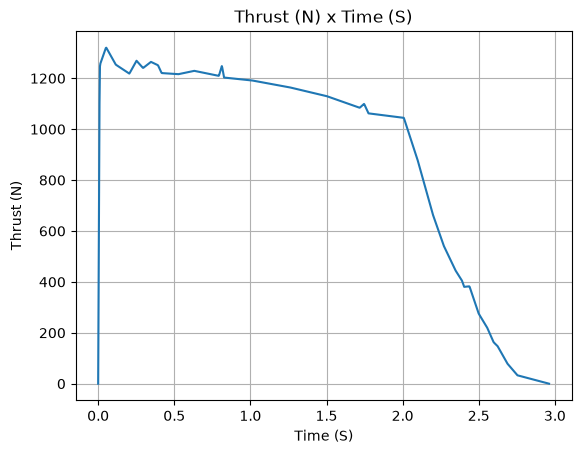

In [30]:
motor = GenericMotor.load_from_eng_file("./rocket_sim_data/AeroTech_L1090W.eng")
motor.info()

/home/lars/miniconda3/envs/simVenv/lib/python3.14/site-packages/rocketpy/mathutils/_calc/polation_1d.py:119: RuntimeWarning: divide by zero encountered in divide
  self._slopes = np.diff(self._y) / np.diff(self._x)
/home/lars/miniconda3/envs/simVenv/lib/python3.14/site-packages/rocketpy/mathutils/_calc/polation_1d.py:119: RuntimeWarning: invalid value encountered in divide
  self._slopes = np.diff(self._y) / np.diff(self._x)


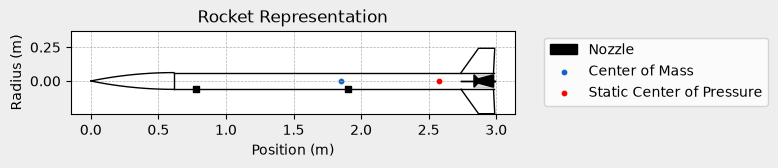

Mass with motor:  16.992
Total impulse: 2698.45275


In [74]:
## We set the coordinate system origin implicitly to the nosecone tip

goldfish = Rocket(
    radius=0.124/2, # 6.2cm radius, checked 
    mass=14.56, ## checked
    inertia=(6.97,6.97,5.27e-2), 
    power_off_drag="./rocket_sim_data/drag_curve_motor_off.csv", # exported
    power_on_drag="./rocket_sim_data/drag_curve_motor_on.csv",
    center_of_mass_without_motor=1.66, ## checked
    coordinate_system_orientation="nose_to_tail", 
)

nose_cone = goldfish.add_nose(
    length=0.615, kind="ogive", position=0
)

fin_set = goldfish.add_trapezoidal_fins(
    n=4,
    root_chord=0.24,
    tip_chord=0.12,
    span=0.18, # == height in openrocket
    position=2.74,
    sweep_length=0.129, ## OR,
    cant_angle=0.0)

rail_buttons = goldfish.set_rail_buttons(
    upper_button_position=0.77825, ## not sure, whether nose cone length includes just the nosecone or also part inside the payload section
    lower_button_position=1.9025, ## as I added up the lengths from OR, same applies here
    angular_position=180,
)

goldfish.add_motor(motor,position=2.98)

goldfish.draw()
print("Mass with motor: ",goldfish.mass + motor.total_mass(0)) # matches open rocket
print("Total impulse:", motor.total_impulse) # also matches open rocket


In [71]:
## Running a simulation
flight = Flight(rocket=goldfish,environment=env,rail_length=2,terminate_on_apogee=True)

Apogee: 1102.667121102223
Max velocity:  132.03204623296946


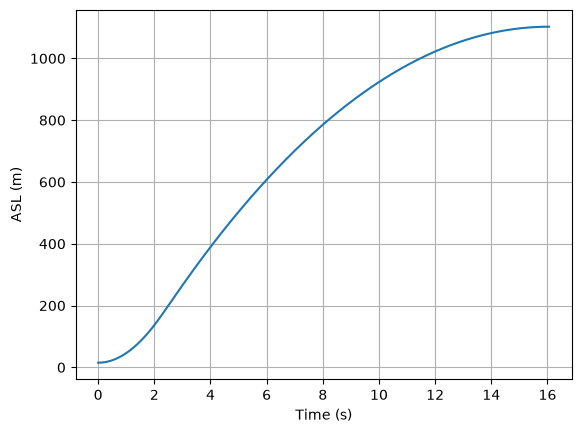

In [73]:
import numpy as np
import matplotlib.pyplot as plt
print(f"Apogee: {flight.apogee}")

# [time, x, y, z, vx, vy, vz, e0, e1, e2, e3, w1, w2, w3]
sol = flight.solution_array

ts = sol[:,0]
altitudes = sol[:,3]
vs = sol[:,6]
print("Max velocity: ",max(vs))

plt.plot(ts,altitudes)
plt.xlabel("Time (s)")
plt.ylabel("ASL (m)")
plt.grid(True)
plt.show()
